# Zeros na demanda e escolha da granularidade

Este notebook responde duas perguntas, sempre com um gráfico para o resultado de cada uma:

- **Parte A — Por que a demanda tem tantos zeros?** Se fosse erro de dado, seria preciso corrigir antes de modelar.
- **Parte B — Em que granularidade prever?** Diária, semanal, mensal ou trimestral, e qual valor exato prever.

**Resposta curta:** os zeros são venda baixa de verdade, não erro. A previsão será feita na **série mensal por produto × loja**, prevendo o **total dos 3 meses seguintes**.

**Em palavras simples:** cada produto, em cada loja, vende muito pouco — em geral só alguns dias por ano. Por isso, olhando dia a dia, quase todo dia aparece "zero vendido" para aquele produto naquela loja. Isso não é um problema nos dados; é assim que esse tipo de negócio vende (poucos itens, pedidos espaçados). A pergunta prática é: em que "janela de tempo" (dia? semana? mês? trimestre?) e prevendo o quê (um mês? três meses?) fica mais fácil enxergar um padrão em vez de só ver zeros?

**Como ler:** cada seção traz a pergunta, o código que calcula a resposta, um gráfico e uma explicação curta do que ele mostra.

| Termo | Significado |
|---|---|
| Série | A demanda de um produto numa loja ao longo do tempo |
| Demanda | Quantidade vendida em pedidos confirmados ou pagos |
| Grão | O tamanho de cada período da série: dia, semana, mês ou trimestre |
| Taxa de zeros | Fração dos períodos sem nenhuma venda |

Os cálculos ficam em `src/analytics_ai/eda_demand_zeros.py`.

## Setup

In [1]:
import sys
from pathlib import Path


def _find_project_root(start: Path) -> Path:
    """Sobe a partir do diretório do notebook até achar a raiz do bundle (databricks.yml)."""
    for candidate in (start, *start.parents):
        if (candidate / "databricks.yml").exists():
            return candidate
    raise FileNotFoundError(f"databricks.yml não encontrado acima de {start}")


# Funciona no workspace (.bundle/.../files/notebooks/ml) e localmente.
PROJECT_ROOT = _find_project_root(Path.cwd())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd
from pyspark.sql import functions as F

from src.analytics_ai.eda_demand_zeros import (
    add_partial_period_flag,
    add_segment_columns,
    aggregate_series,
    horizon_target_comparison,
    order_status_filter_impact,
    seasonal_signal_share,
    zero_rate_by,
    zero_rate_by_volume_decile,
    zero_rate_overall,
    zero_rows_from_trailing_dead_combinations,
)
from src.analytics_ai.ml_config import MlFeatureConfig

# No Databricks o notebook já expõe `spark`; localmente cria via Databricks Connect
# (defina DATABRICKS_PROFILE com o nome do seu profile em ~/.databrickscfg).
spark = globals().get("spark")
if spark is None:
    from src.ingestion.utils import build_spark_session

    spark = build_spark_session()

# Databricks e Jupyter injetam `display`; fora deles, cai para print.
display = globals().get("display", print)

plt.rcParams["figure.dpi"] = 100
CORES = ["#2E5C8A", "#E8874C", "#4C9A6A", "#B24C4C"]

# Grãos do mais fino ao mais agregado.
GRAINS = MlFeatureConfig.all_grains()
DFS = {name: spark.table(config.source_table) for name, config in GRAINS.items()}
daily_config, daily_df = GRAINS["diario"], DFS["diario"]

for name, config in GRAINS.items():
    print(f"{name:<11} {config.source_table}")

diario      dev_lh_nautical.ml.agg_demand_daily
semanal     dev_lh_nautical.ml.agg_demand_weekly
mensal      dev_lh_nautical.ml.agg_demand_monthly
trimestral  dev_lh_nautical.ml.agg_demand_quarterly


# Parte A — Por que tantos zeros?

## A1. Quanto da demanda é zero em cada grão?

**Como medimos:** fração dos períodos sem venda em cada uma das quatro tabelas.

,n_rows,n_zero_rows,n_combinations,zero_rate
grao,,,,
diario,13840555,13722583,6054,0.9915
semanal,1981509,1866999,6054,0.9422
mensal,460030,357610,6054,0.7774
trimestral,154993,75050,6054,0.4842


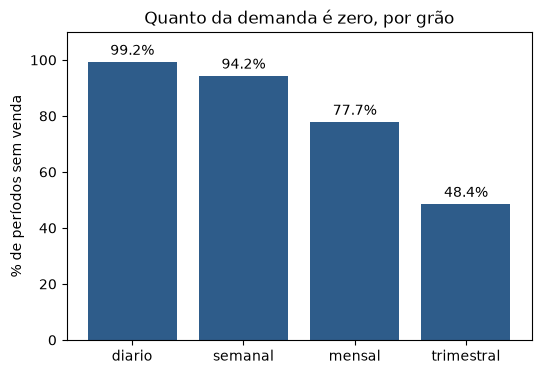

In [3]:
zero_by_grain = pd.concat(
    [
        zero_rate_overall(df, GRAINS[name].target_col, GRAINS[name].id_cols).toPandas().assign(grao=name)
        for name, df in DFS.items()
    ]
).set_index("grao").loc[list(GRAINS)]

display(zero_by_grain)

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(zero_by_grain.index, zero_by_grain["zero_rate"] * 100, color=CORES[0])
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_ylim(0, 110)
ax.set_ylabel("% de períodos sem venda")
ax.set_title("Quanto da demanda é zero, por grão")
plt.show()

**O que o gráfico mostra:** agregar reduz bastante os zeros, mas mesmo no mensal 3 em cada 4 meses de uma série não têm venda. As seções seguintes investigam a causa.

## A2. Os zeros se concentram em algum grupo?

**Como medimos:** taxa de zeros no grão diário, separada por alta temporada e por tipo de loja. O diário é usado porque cada dia fica inteiro dentro ou fora da alta temporada, enquanto uma semana ou um mês pode ficar dividido.

**Por que importa:** se um grupo concentrasse os zeros, haveria uma causa específica para investigar ou tratar à parte.

C:\indicium_ai\athena\lh_nautical\.venv\Lib\site-packages\pyspark\sql\connect\expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


C:\indicium_ai\athena\lh_nautical\.venv\Lib\site-packages\pyspark\sql\connect\expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


C:\indicium_ai\athena\lh_nautical\.venv\Lib\site-packages\pyspark\sql\connect\expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


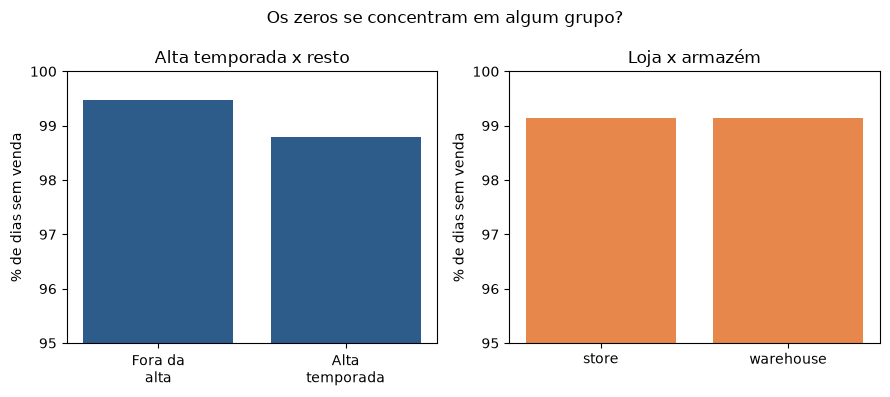

Categorias: entre 99.1% e 99.2% — todas parecidas.


In [4]:
daily_segmented = add_segment_columns(daily_df, daily_config.gold_table, date_col=daily_config.date_col)

season = zero_rate_by(daily_segmented, ["is_high_season"]).toPandas()
store_type = zero_rate_by(daily_segmented, ["location_type"]).toPandas()
by_category = zero_rate_by(daily_segmented, ["category_name"]).toPandas()

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

season_labels = season["is_high_season"].map({True: "Alta\ntemporada", False: "Fora da\nalta"})
axes[0].bar(season_labels, season["zero_rate"] * 100, color=CORES[0])
axes[0].set_title("Alta temporada x resto")

axes[1].bar(store_type["location_type"], store_type["zero_rate"] * 100, color=CORES[1])
axes[1].set_title("Loja x armazém")

for ax in axes:
    ax.set_ylim(95, 100)
    ax.set_ylabel("% de dias sem venda")

plt.suptitle("Os zeros se concentram em algum grupo?")
plt.tight_layout()
plt.show()

print(f"Categorias: entre {by_category['zero_rate'].min():.1%} e {by_category['zero_rate'].max():.1%} — todas parecidas.")

**O que o gráfico mostra:** a diferença entre alta temporada e o resto parece pequena, mas não significa que a estação é fraca — com chance de venda tão baixa por dia, até uma demanda bem maior aparece como diferença pequena na taxa de zeros (a B4 mostra que a estação é forte). Loja e armazém dividem os zeros quase meio a meio, e as categorias ficam todas numa faixa estreita. **Nenhum grupo concentra os zeros** — não há um segmento problemático para tratar à parte.

## A3. Produtos que vendem mais têm menos zeros?

**Como medimos:** as séries são ordenadas pelo volume total e divididas em 10 faixas iguais (decis). Decil 1 = as 10% que menos vendem; decil 10 = as 10% que mais vendem.

**Por que importa:** se os zeros fossem só dos produtos de venda baixa, bastaria separar esses produtos.

C:\indicium_ai\athena\lh_nautical\.venv\Lib\site-packages\pyspark\sql\connect\expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


C:\indicium_ai\athena\lh_nautical\.venv\Lib\site-packages\pyspark\sql\connect\expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


C:\indicium_ai\athena\lh_nautical\.venv\Lib\site-packages\pyspark\sql\connect\expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


C:\indicium_ai\athena\lh_nautical\.venv\Lib\site-packages\pyspark\sql\connect\expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


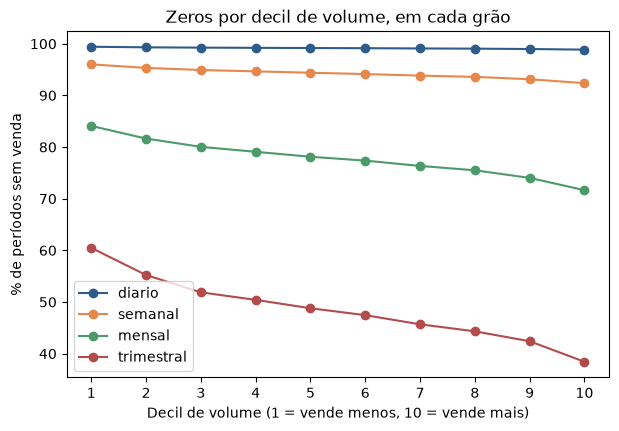

In [5]:
deciles = pd.concat(
    [
        zero_rate_by_volume_decile(df, id_cols=GRAINS[name].id_cols)
        .select("volume_decile", "zero_rate")
        .toPandas()
        .assign(grao=name)
        for name, df in DFS.items()
    ]
)
pivot_deciles = deciles.pivot(index="volume_decile", columns="grao", values="zero_rate")[list(GRAINS)] * 100

fig, ax = plt.subplots(figsize=(7, 4.5))
for grao, cor in zip(pivot_deciles.columns, CORES):
    ax.plot(pivot_deciles.index, pivot_deciles[grao], marker="o", label=grao, color=cor)
ax.set_xticks(range(1, 11))
ax.set_xlabel("Decil de volume (1 = vende menos, 10 = vende mais)")
ax.set_ylabel("% de períodos sem venda")
ax.set_title("Zeros por decil de volume, em cada grão")
ax.legend()
plt.show()

**O que o gráfico mostra:** até os produtos que mais vendem (decil 10) passam quase todos os dias sem venda. A diferença entre alto e baixo giro só aparece de forma clara a partir do mensal. Os zeros não são exclusividade de um grupo de produtos fracos: é o jeito como esse negócio vende.

## A4. Os zeros vêm de produtos que pararam de vender?

**Como medimos:** uma série é considerada **parada** quando a última venda aconteceu mais de 90 dias antes do fim do dataset. O gráfico mostra qual fração dos zeros vem dos períodos depois da última venda dessas séries.

**Por que importa:** a tabela diária registra zero até o fim do dataset mesmo para produtos que saíram de linha. Se essa fração fosse grande, a correção seria no dbt, não no modelo.

,n_combinations,n_dead_combinations,trailing_dead_share_of_zeros
grao,,,
diario,6054,3481,0.0464
semanal,6054,3527,0.0488
mensal,6054,3722,0.0596
trimestral,6054,3722,0.0799


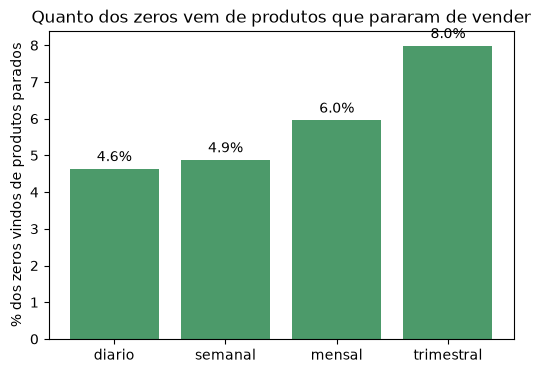

In [6]:
dead = pd.concat(
    [
        zero_rows_from_trailing_dead_combinations(df, date_col=GRAINS[name].date_col, dead_after_days=90)
        .toPandas()
        .assign(grao=name)
        for name, df in DFS.items()
    ]
).set_index("grao").loc[list(GRAINS)]

display(dead[["n_combinations", "n_dead_combinations", "trailing_dead_share_of_zeros"]])

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(dead.index, dead["trailing_dead_share_of_zeros"] * 100, color=CORES[2])
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_ylabel("% dos zeros vindos de produtos parados")
ax.set_title("Quanto dos zeros vem de produtos que pararam de vender")
plt.show()

**O que o gráfico mostra:** mesmo com boa parte das séries sem venda há mais de 90 dias, os períodos depois da última venda respondem por uma fatia pequena dos zeros em todos os grãos. **Produtos parados não explicam os zeros.** Para o modelo, séries paradas ficam fora do treino e recebem previsão zero por regra.

## A5. A definição de demanda está descartando vendas?

**Como medimos:** a demanda só conta itens de pedidos confirmados ou pagos. O gráfico mostra quanto da quantidade cada situação de pedido representa e se entra na demanda (verde) ou não (vermelho).

**Por que importa:** se o filtro descartasse muita venda real, parte dos zeros seria criada pela própria regra.

C:\indicium_ai\athena\lh_nautical\.venv\Lib\site-packages\pyspark\sql\connect\expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


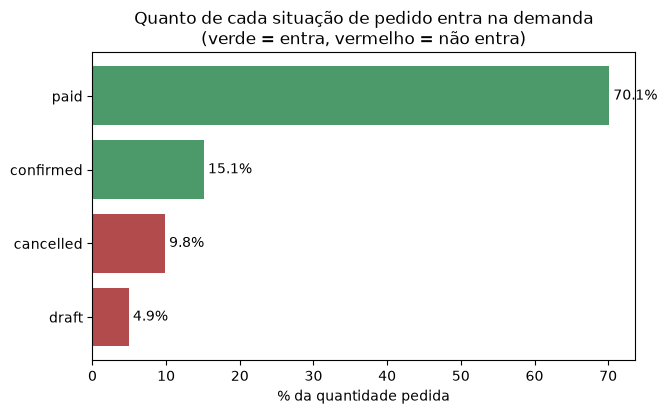

In [7]:
status = order_status_filter_impact(spark.table(daily_config.gold_table("fact_order_items"))).toPandas()
cores_status = status["included_in_demand"].map({True: CORES[2], False: CORES[3]})

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.barh(status["order_status"], status["share_of_quantity"] * 100, color=cores_status)
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_xlabel("% da quantidade pedida")
ax.set_title("Quanto de cada situação de pedido entra na demanda\n(verde = entra, vermelho = não entra)")
ax.invert_yaxis()
plt.show()

**O que o gráfico mostra:** a regra descarta uma fatia da quantidade, formada por pedidos cancelados e rascunhos. É uma exclusão correta — bem menor do que os ~99% de dias sem venda — e não explica os zeros.

## Resposta da Parte A

**Os zeros são venda baixa de verdade, não erro de dado.**

- Não vêm de um grupo específico (A2), nem só dos produtos fracos (A3), nem de produtos parados (A4), nem da regra de demanda (A5).
- A causa é o volume: uma série típica vende só em poucos dias, em vários anos de dados.

**Consequência:** os zeros ficam nos dados. O trabalho é escolher uma forma de prever que funcione com eles (Parte B).

# Parte B — Em que granularidade prever?

## B1. O que torna uma granularidade boa

Agregar sempre reduz zeros, então "menos zeros" sozinho levaria direto ao trimestral. A escolha equilibra ganhos e perdas:

| Critério | Pergunta | Onde é medido |
|---|---|---|
| Poucos zeros | O modelo terá algo além de zero para aprender? | B2, B3 |
| Histórico suficiente | Quantos pontos cada série tem para treinar? | B3 |
| Horizonte flexível | Quantos passos até cobrir os 3 meses do plano? | B3 |
| Sinal da estação | Quanto da variação a estação explica? | B4 e B5 |
| Ruído do alvo | Quanto do valor previsto é variação aleatória? | B6 |

## B2. Períodos incompletos

**Como medimos:** um período é incompleto quando tem menos dias que o calendário (o primeiro período de cada série, e o último do dataset). O gráfico compara a taxa de zeros de períodos completos e incompletos.

**Por que importa:** períodos incompletos distorcem a série e precisam ficar fora das comparações e do treino.

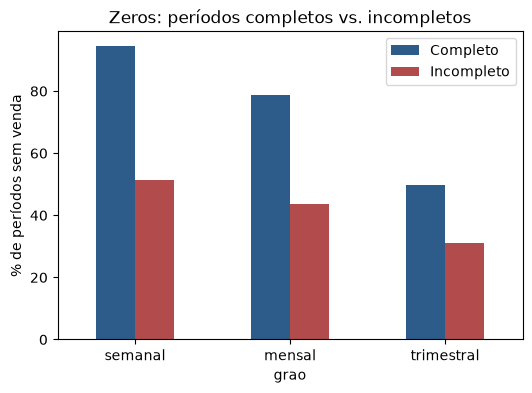

In [8]:
partial_rows = []
for name, df in DFS.items():
    if name == "diario":
        continue
    flagged = add_partial_period_flag(df, GRAINS[name].date_col, GRAINS[name].grain)
    agg = flagged.groupBy("is_partial_period").agg(
        F.round(F.mean((F.col("demand_quantity") == 0).cast("int")), 4).alias("zero_rate")
    ).toPandas()
    agg["grao"] = name
    partial_rows.append(agg)

partial_pivot = (
    pd.concat(partial_rows)
    .pivot(index="grao", columns="is_partial_period", values="zero_rate")
    .reindex(columns=[False, True])
    .loc[["semanal", "mensal", "trimestral"]]
    * 100
)
partial_pivot.columns = ["Completo", "Incompleto"]

fig, ax = plt.subplots(figsize=(6, 4))
partial_pivot.plot(kind="bar", ax=ax, color=[CORES[0], CORES[3]])
ax.set_ylabel("% de períodos sem venda")
ax.set_title("Zeros: períodos completos vs. incompletos")
plt.xticks(rotation=0)
plt.show()

**O que o gráfico mostra:** os períodos incompletos têm **menos** zeros, não mais — o primeiro período de cada série sempre tem venda, porque a série começa justamente nela. Eles distorcem a série e ficam fora de todas as comparações e do treino. O trimestral é o grão mais afetado, por ter os períodos mais longos.

## B3. Histórico e horizonte de cada grão

**Como medimos:** para cada grão, só com períodos completos, quantos pontos de histórico uma série típica tem e em quantos passos o horizonte de 3 meses é coberto.

,pontos_por_serie,passos_ate_3_meses
grao,,
diario,2286.2,91
semanal,325.4,13
mensal,74.0,3
trimestral,23.6,1


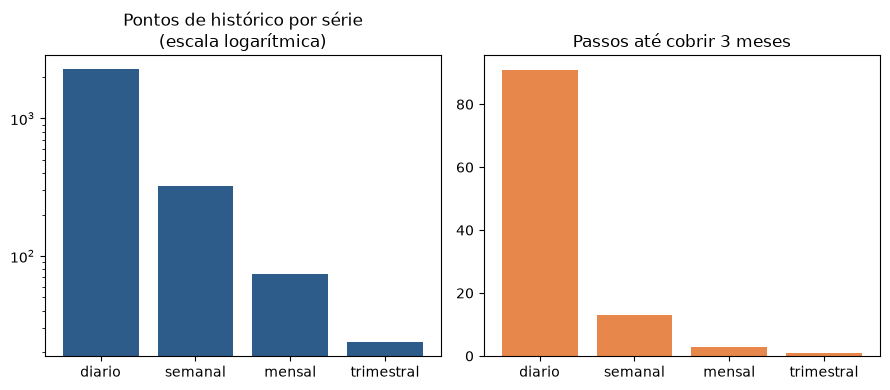

In [9]:
scorecard_rows = []
for name, config in GRAINS.items():
    complete = add_partial_period_flag(DFS[name], config.date_col, config.grain).filter(~F.col("is_partial_period"))
    stats = complete.agg(
        F.count("*").alias("n_rows"),
        F.countDistinct(*config.id_cols).alias("n_series"),
    ).first()
    scorecard_rows.append(
        {
            "grao": name,
            "pontos_por_serie": stats["n_rows"] / stats["n_series"],
            "passos_ate_3_meses": config.horizon_periods,
        }
    )

scorecard = pd.DataFrame(scorecard_rows).set_index("grao").loc[list(GRAINS)]
display(scorecard.round(1))

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].bar(scorecard.index, scorecard["pontos_por_serie"], color=CORES[0])
axes[0].set_yscale("log")
axes[0].set_title("Pontos de histórico por série\n(escala logarítmica)")
axes[1].bar(scorecard.index, scorecard["passos_ate_3_meses"], color=CORES[1])
axes[1].set_title("Passos até cobrir 3 meses")
plt.tight_layout()
plt.show()

**O que o gráfico mostra:** diário e semanal têm muitos pontos de histórico, mas isso não compensa a taxa de zeros de mais de 90% vista em A1. O trimestral tem pouquíssimos pontos por série (dificulta o aprendizado) e só permite começar a prever a partir de janeiro, abril, julho ou outubro (4 passos por ano). O mensal equilibra as duas coisas: histórico razoável e previsão a partir de qualquer mês, cobrindo os 3 meses em 3 passos.

## B4. A demanda tem estação?

**Como medimos:** para cada mês do ano, a demanda média ao longo dos anos, dividida pela média dos 12 meses (**índice sazonal**; 1,0 = mês típico). Um mês é **alta temporada** quando fica acima da média.

,month_number,complete_months_count,avg_monthly_demand,overall_avg_monthly_demand,seasonal_index,is_high_season
0,1,6,14497.67,8185.30,1.7712,True
1,2,7,11386.00,8185.30,1.3910,True
2,3,7,11170.86,8185.30,1.3647,True
3,4,7,8565.29,8185.30,1.0464,True
4,5,7,5824.29,8185.30,0.7116,False
5,6,7,3867.71,8185.30,0.4725,False
6,7,7,3413.43,8185.30,0.4170,False
7,8,7,4191.86,8185.30,0.5121,False
8,9,6,5273.00,8185.30,0.6442,False
9,10,6,8106.83,8185.30,0.9904,False


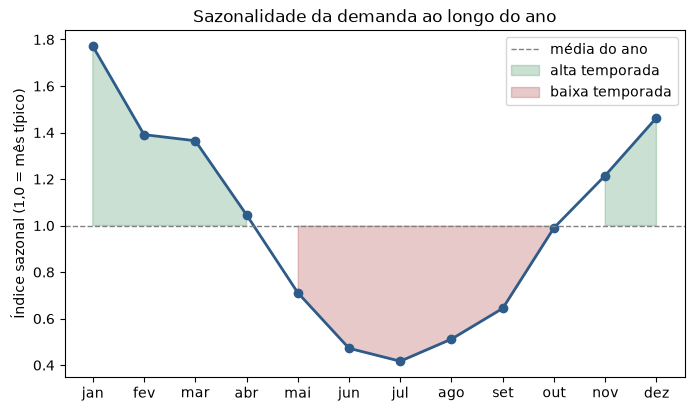

In [10]:
season_by_month = spark.table(daily_config.silver_table("int_high_season_months")).orderBy("month_number").toPandas()
display(season_by_month)

meses = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(season_by_month["month_number"], season_by_month["seasonal_index"], marker="o", color=CORES[0], linewidth=2)
ax.axhline(1.0, color="gray", linestyle="--", linewidth=1, label="média do ano")
ax.fill_between(
    season_by_month["month_number"], 1.0, season_by_month["seasonal_index"],
    where=season_by_month["seasonal_index"] > 1, color=CORES[2], alpha=0.3, label="alta temporada",
)
ax.fill_between(
    season_by_month["month_number"], 1.0, season_by_month["seasonal_index"],
    where=season_by_month["seasonal_index"] <= 1, color=CORES[3], alpha=0.3, label="baixa temporada",
)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(meses)
ax.set_ylabel("Índice sazonal (1,0 = mês típico)")
ax.set_title("Sazonalidade da demanda ao longo do ano")
ax.legend()
plt.show()

**O que o gráfico mostra:** a estação é forte — janeiro vende bem mais que julho. A alta temporada vai de novembro a abril. Para o modelo, a marcação "alta/baixa temporada" sozinha é grosseira, porque trata meses de fronteira quase como os de pico; por isso o **índice sazonal** dos meses previstos entra como informação, não só a marcação binária.

## B5. Quanto da variação a estação explica?

**Como medimos:** para cada série, prevemos cada período como "média da série × índice do mês" e medimos quanto da variação essa conta explica (0% = a estação não aparece; 100% = a série é só estação). Comparamos dois níveis:

- **produto × loja:** a série que vamos prever;
- **categoria × loja:** os produtos da mesma categoria somados.

,produto × loja,categoria × loja
grao,,
diario,0.1,7.5
semanal,0.9,31.5
mensal,3.8,55.1
trimestral,9.3,61.8


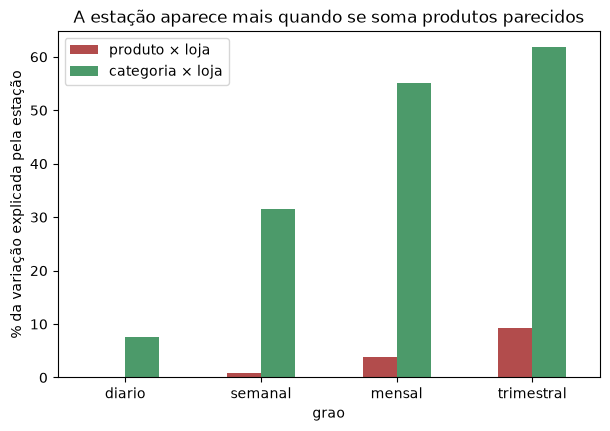

In [11]:
segmented_all = add_segment_columns(daily_df, daily_config.gold_table, date_col=None)
LEVELS = {
    "produto_x_loja": ["sk_product", "sk_location"],
    "categoria_x_loja": ["category_name", "sk_location"],
}

signal_rows = []
for level, ids in LEVELS.items():
    for name, config in GRAINS.items():
        series = aggregate_series(segmented_all, ids, config.grain).filter(~F.col("is_partial_period"))
        r2 = seasonal_signal_share(series, "period_start_date", ids).collect()[0]["r2_seasonal"]
        signal_rows.append({"nivel": level, "grao": name, "r2_seasonal": r2})

signal = pd.DataFrame(signal_rows)
pivot_signal = signal.pivot(index="grao", columns="nivel", values="r2_seasonal")[list(LEVELS)].loc[list(GRAINS)] * 100
pivot_signal.columns = ["produto × loja", "categoria × loja"]
display(pivot_signal.round(1))

fig, ax = plt.subplots(figsize=(7, 4.5))
pivot_signal.plot(kind="bar", ax=ax, color=[CORES[3], CORES[2]])
ax.set_ylabel("% da variação explicada pela estação")
ax.set_title("A estação aparece mais quando se soma produtos parecidos")
plt.xticks(rotation=0)
plt.show()

**O que o gráfico mostra:** numa série produto × loja, a estação explica muito pouco da variação mensal — o resto é ruído de venda. Somando os produtos da mesma categoria na loja, a estação explica boa parte da variação: o sinal aparece quando se junta produtos parecidos. **Consequência para o modelo:** a previsão continua sendo por produto × loja, mas o modelo deve receber informação de produtos parecidos, como a venda da categoria na mesma loja.

## B6. O que prever: um mês ou o total de 3 meses?

**Como medimos:** na série mensal (meses completos), comparamos dois alvos possíveis: a demanda de um único mês, e a soma dos 3 meses seguintes. Para cada alvo: a taxa de zeros e o **ruído relativo**, o tamanho aproximado da variação aleatória em relação à média — o erro que sobra mesmo com um modelo perfeito.

,alvo,n_targets,zero_rate,mean_target,median_dispersion,noise_ratio
0,um mês,448175,0.7864,1.365,6.94,2.25
1,total de 3 meses,430013,0.4996,4.135,7.14,1.31


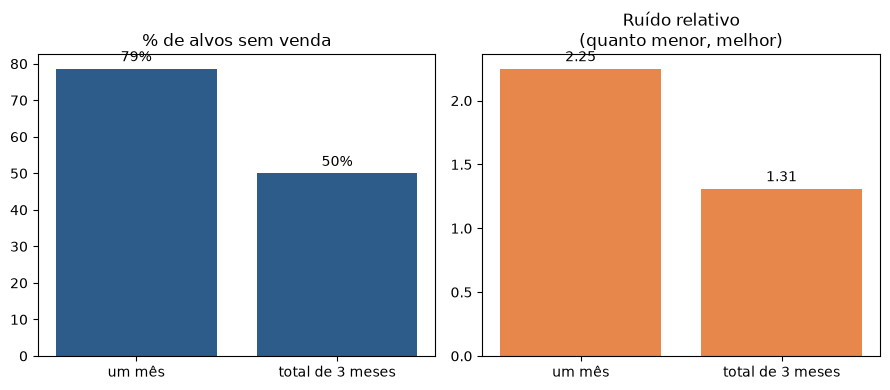

In [12]:
monthly_config = GRAINS["mensal"]
monthly_complete = add_partial_period_flag(DFS["mensal"], monthly_config.date_col, "month").filter(
    ~F.col("is_partial_period")
)

horizon_cmp = horizon_target_comparison(monthly_complete, monthly_config.date_col, horizon=3).toPandas()
display(horizon_cmp)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
bars0 = axes[0].bar(horizon_cmp["alvo"], horizon_cmp["zero_rate"] * 100, color=CORES[0])
axes[0].bar_label(bars0, fmt="%.0f%%", padding=3)
axes[0].set_title("% de alvos sem venda")

bars1 = axes[1].bar(horizon_cmp["alvo"], horizon_cmp["noise_ratio"], color=CORES[1])
axes[1].bar_label(bars1, fmt="%.2f", padding=3)
axes[1].set_title("Ruído relativo\n(quanto menor, melhor)")

plt.tight_layout()
plt.show()

**O que o gráfico mostra:** prever o total dos 3 meses seguintes corta bastante a fatia de alvos sem venda e reduz o ruído relativo quase pela metade. Mesmo um modelo perfeito erraria o total de 3 meses de uma série em algo do tamanho da própria média — esse é o piso de erro por série. Por isso escolhemos prever o total de 3 meses: não elimina o acaso, mas reduz bastante o piso de erro que nenhum modelo consegue superar.

## Conclusão

**Em uma frase, para quem não trabalha com dados:** a venda de cada produto numa loja é naturalmente rala e cheia de "zeros" — isso não é erro de dado, é assim que o negócio vende — e a forma que melhor equilibra ter poucos zeros com ter histórico suficiente para aprender é olhar mês a mês e prever o total dos 3 meses seguintes, em vez de olhar dia a dia ou prever só o próximo mês.

| Decisão | Por quê | Seção |
|---|---|---|
| **Manter os zeros** | São venda baixa real, não erro de dado | Parte A |
| **Série mensal por produto × loja** | Diário e semanal têm zeros demais; o trimestral tem pouco histórico e só prevê a partir de inícios de trimestre | B3 |
| **Alvo = total dos 3 meses seguintes** | Menos alvos zerados e metade do ruído, contra prever um mês isolado | B6 |
| **Remover períodos incompletos** | Distorcem a série: o primeiro sempre tem venda | B2 |
| **Usar o sinal de produtos parecidos como feature** | A estação some dentro de uma série, mas aparece quando os produtos da categoria na loja são somados | B5 |
| **Usar o índice sazonal, não só a alta temporada** | A marcação binária trata meses de fronteira quase como os de pico | B4 |

**Próximo passo:** o notebook `02_distribuicao_produtos` divide as séries em grupos e define o que cada grupo recebe nas etapas seguintes.